In [1]:
## 1. Setup, fixed seeds and persistent output directory

In [2]:
%pip -q install "mlflow>=2.20,<4" "google-cloud-storage>=2.14,<4" "gcsfs>=2024.1" "scikit-learn>=1.4,<2" "psutil>=5.9" "joblib>=1.3"

In [3]:
import os, sys, json, time, random, hashlib, platform, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, mlflow, psutil, joblib
from google.colab import auth, drive
from google.cloud import storage
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, ParameterSampler
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.base import clone
SEED=42
random.seed(SEED); np.random.seed(SEED)
drive.mount('/content/drive')
ROOT=Path('/content/drive/MyDrive/IMDB_Milestone3')
for sub in ['artifacts','figures','mlruns','reports']:(ROOT/sub).mkdir(parents=True,exist_ok=True)
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
mlflow.set_tracking_uri((ROOT/'mlruns').as_uri())
mlflow.set_experiment('IMDB_Milestone3_TFIDF_Models')
print('Python',sys.version,'sklearn',sklearn.__version__,'MLflow',mlflow.__version__)
print('CPU cores',os.cpu_count(),'RAM GB',round(psutil.virtual_memory().total/1e9,2))

Mounted at /content/drive
Python 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0] sklearn 1.6.1 MLflow 3.18.0
CPU cores 2 RAM GB 13.61


In [4]:
## 2. Read Milestone 2 GCS shards and audit for leakage

In [5]:
auth.authenticate_user()
PROJECT_ID='dh-and-infra-for-ai';
BUCKET='imdb-sentiment-project'
client=storage.Client(project=PROJECT_ID); bucket=client.bucket(BUCKET)
parts={}
for part in ['train','dev','test']:
    blob=bucket.blob(f'sharded/{part}.csv')
    if not blob.exists(): raise FileNotFoundError(f'Missing gs://{BUCKET}/sharded/{part}.csv')
    local=ROOT/'artifacts'/f'original_{part}.csv'
    blob.download_to_filename(str(local))
    d=pd.read_csv(local)
    assert {'review','sentiment'}.issubset(d.columns)
    d=d[['review','sentiment']].dropna().copy()
    d['sentiment']=d['sentiment'].astype(str).str.lower().str.strip()
    assert set(d.sentiment.unique()) <= {'positive','negative'}
    d['review']=d['review'].astype(str)
    parts[part]=d
    print(part, len(d), d.sentiment.value_counts().to_dict())
all_rows=pd.concat([d.assign(partition=k) for k,d in parts.items()],ignore_index=True)
conflicts=all_rows.groupby('review')['sentiment'].nunique()
print('Conflicting-label review texts:',int((conflicts>1).sum()))
print('Exact text overlaps train/dev:',len(set(parts['train'].review)&set(parts['dev'].review)))
print('Exact text overlaps train/test:',len(set(parts['train'].review)&set(parts['test'].review)))
print('Exact text overlaps dev/test:',len(set(parts['dev'].review)&set(parts['test'].review)))

train 40000 {'positive': 20000, 'negative': 20000}
dev 5000 {'negative': 2500, 'positive': 2500}
test 5000 {'negative': 2500, 'positive': 2500}
Conflicting-label review texts: 0
Exact text overlaps train/dev: 62
Exact text overlaps train/test: 80
Exact text overlaps dev/test: 9


In [6]:
# Preserve test first, then dev; remove exact duplicates and cross-partition overlaps.
# Any duplicate text with contradictory labels is removed from ALL partitions.

In [7]:
conflict_texts=set(conflicts[conflicts>1].index)
test_df=parts['test'].loc[~parts['test'].review.isin(conflict_texts)].drop_duplicates('review').copy()
dev_df=parts['dev'].loc[~parts['dev'].review.isin(conflict_texts | set(test_df.review))].drop_duplicates('review').copy()
train_df=parts['train'].loc[~parts['train'].review.isin(conflict_texts | set(test_df.review) | set(dev_df.review))].drop_duplicates('review').copy()
assert len(set(train_df.review)&set(dev_df.review))==0
assert len(set(train_df.review)&set(test_df.review))==0
assert len(set(dev_df.review)&set(test_df.review))==0
assert min(len(train_df),len(dev_df),len(test_df))>0
for name,frame in [('train',train_df),('dev',dev_df),('test',test_df)]:
    frame['label']=frame.sentiment.map({'negative':0,'positive':1}).astype(int)
    frame.to_csv(ROOT/'artifacts'/f'audited_{name}.csv',index=False)
    print(name,len(frame),frame.label.value_counts().to_dict())
# Avoid fitting text preprocessing on any holdout data.
X_train=train_df.review.reset_index(drop=True); y_train=train_df.label.reset_index(drop=True)
X_dev=dev_df.review.reset_index(drop=True); y_dev=dev_df.label.reset_index(drop=True)
# Test labels are intentionally NOT accessed again until section 8.


train 39601 {1: 19893, 0: 19708}
dev 4988 {0: 2494, 1: 2494}
test 4993 {1: 2497, 0: 2496}


In [8]:
## 3. Model selection

In [9]:
def make_pipeline(model):
    return Pipeline([
        ('tfidf',TfidfVectorizer(lowercase=True,strip_accents='unicode',
                                 token_pattern=r'(?u)\b\w+\b',dtype=np.float32)),
        ('clf',model)
    ])
models={
 'NaiveBayes':make_pipeline(MultinomialNB()),
 'LogisticRegression':make_pipeline(LogisticRegression(max_iter=1500,random_state=SEED)),
 'LinearSVM':make_pipeline(LinearSVC(random_state=SEED,max_iter=5000))
}
def metrics(y_true,y_pred):
    p,r,f,_=precision_recall_fscore_support(y_true,y_pred,average='macro',zero_division=0)
    return {'accuracy':float(accuracy_score(y_true,y_pred)),'precision_macro':float(p),
            'recall_macro':float(r),'f1_macro':float(f)}

In [10]:
## 4. Baseline experiments with MLflow

In [11]:
baseline_rows=[]
for name,pipe in models.items():
    with mlflow.start_run(run_name=f'baseline_{name}'):
        t=time.perf_counter(); pipe.fit(X_train,y_train); duration=time.perf_counter()-t
        pred=pipe.predict(X_dev); scores=metrics(y_dev,pred)
        mlflow.log_params({'model_type':name,'phase':'baseline','seed':SEED,
                           'train_rows':len(X_train),'dev_rows':len(X_dev)})
        mlflow.log_metrics({f'dev_{k}':v for k,v in scores.items()})
        mlflow.log_metric('train_seconds',duration)
        mlflow.log_param('cpu_cores',os.cpu_count())
        mlflow.sklearn.log_model(pipe,name='model')
        baseline_rows.append({'model':name,'phase':'baseline','train_seconds':duration,**scores})
baselines=pd.DataFrame(baseline_rows).sort_values('f1_macro',ascending=False)
display(baselines)
baselines.to_csv(ROOT/'artifacts'/'baseline_comparison.csv',index=False)

,model,phase,train_seconds,accuracy,precision_macro,recall_macro,f1_macro
2,LinearSVM,baseline,11.499961,0.905974,0.906268,0.905974,0.905957
1,LogisticRegression,baseline,15.762015,0.903168,0.903778,0.903168,0.903131
0,NaiveBayes,baseline,10.418664,0.868083,0.868283,0.868083,0.868066


In [12]:
## 5. Systematic hyperparameter search

In [13]:
search_spaces={
 'NaiveBayes':{'tfidf__ngram_range':[(1,1),(1,2)],'tfidf__min_df':[2,5],
               'tfidf__max_features':[20000,50000],'clf__alpha':[0.1,0.5,1.0,2.0]},
 'LogisticRegression':{'tfidf__ngram_range':[(1,1),(1,2)],'tfidf__min_df':[2,5],
                       'tfidf__max_features':[20000,50000],'clf__C':[0.1,1.0,3.0,10.0]},
 'LinearSVM':{'tfidf__ngram_range':[(1,1),(1,2)],'tfidf__min_df':[2,5],
              'tfidf__max_features':[20000,50000],'clf__C':[0.1,0.5,1.0,3.0]}
}
N_TRIALS=4; N_FOLDS=3
cv=StratifiedKFold(n_splits=N_FOLDS,shuffle=True,random_state=SEED)
trials=[]; best_cv={}
for model_name,template in models.items():
    candidates=list(ParameterSampler(search_spaces[model_name],n_iter=N_TRIALS,random_state=SEED))
    for trial_id,params in enumerate(candidates):
        run_name=f'tune_{model_name}_{trial_id:02d}'
        with mlflow.start_run(run_name=run_name):
            mlflow.log_params({'model_type':model_name,'phase':'tuning','trial':trial_id,
                               'cv_folds':N_FOLDS,'seed':SEED,**{k:str(v) for k,v in params.items()}})
            scores=[]; start=time.perf_counter()
            for fold,(tr,va) in enumerate(cv.split(X_train,y_train)):
                pipe=clone(template).set_params(**params)
                pipe.fit(X_train.iloc[tr],y_train.iloc[tr])
                pred=pipe.predict(X_train.iloc[va])
                fold_f1=metrics(y_train.iloc[va],pred)['f1_macro']
                scores.append(fold_f1)
                mlflow.log_metric('fold_f1_macro',fold_f1,step=fold)
            elapsed=time.perf_counter()-start
            mean_f1=float(np.mean(scores)); std_f1=float(np.std(scores))
            mlflow.log_metrics({'cv_mean_f1_macro':mean_f1,'cv_std_f1_macro':std_f1,
                                'cv_train_seconds':elapsed})
            record={'model':model_name,'trial':trial_id,'cv_mean_f1_macro':mean_f1,
                    'cv_std_f1_macro':std_f1,'cv_train_seconds':elapsed,'params':params}
            trials.append(record)
            pd.DataFrame([{**{k:v for k,v in t.items() if k!='params'},
                           'params_json':json.dumps(t['params'])} for t in trials]).to_csv(
                           ROOT/'artifacts'/'tuning_trials.csv',index=False)
    best_cv[model_name]=max([t for t in trials if t['model']==model_name],key=lambda x:x['cv_mean_f1_macro'])
print('Best CV configuration per model:')
for name,rec in best_cv.items():print(name,rec['cv_mean_f1_macro'],rec['params'])

Best CV configuration per model:
NaiveBayes 0.882137300157701 {'tfidf__ngram_range': (1, 2), 'tfidf__min_df': 5, 'tfidf__max_features': 50000, 'clf__alpha': 0.5}
LogisticRegression 0.9089520673296043 {'tfidf__ngram_range': (1, 2), 'tfidf__min_df': 2, 'tfidf__max_features': 50000, 'clf__C': 10.0}
LinearSVM 0.9087989554817092 {'tfidf__ngram_range': (1, 2), 'tfidf__min_df': 5, 'tfidf__max_features': 50000, 'clf__C': 0.5}


In [14]:
## 6. Retrain tuned candidates and compare dev performance

,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,inference_ms_per_review,cv_mean_f1_macro
1,LogisticRegression,0.922013,0.922336,0.922013,0.921998,50.695279,0.567353,0.908952
2,LinearSVM,0.921010,0.921342,0.921010,0.920995,54.251260,0.639150,0.908799
0,NaiveBayes,0.892141,0.892177,0.892141,0.892139,40.468144,0.758563,0.882137


Selected using DEVELOPMENT F1: LogisticRegression


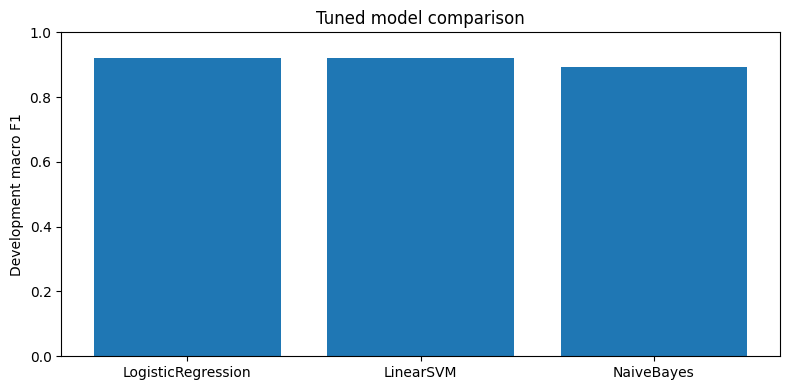

In [15]:
tuned_models={}; results=[]
for name,rec in best_cv.items():
    model=clone(models[name]).set_params(**rec['params'])
    start=time.perf_counter(); model.fit(X_train,y_train); fit_s=time.perf_counter()-start
    start=time.perf_counter(); pred=model.predict(X_dev); infer_s=time.perf_counter()-start
    score=metrics(y_dev,pred)
    with mlflow.start_run(run_name=f'tuned_final_{name}'):
        mlflow.log_params({'model_type':name,'phase':'tuned_dev','seed':SEED,
                           **{k:str(v) for k,v in rec['params'].items()}})
        mlflow.log_metrics({f'dev_{k}':v for k,v in score.items()})
        mlflow.log_metrics({'fit_seconds':fit_s,'inference_seconds':infer_s,
                            'inference_ms_per_review':1000*infer_s/len(X_dev),
                            'cv_mean_f1_macro':rec['cv_mean_f1_macro']})
        mlflow.sklearn.log_model(model,name='model')
    tuned_models[name]=model
    results.append({'model':name,**score,'fit_seconds':fit_s,
                    'inference_ms_per_review':1000*infer_s/len(X_dev),
                    'cv_mean_f1_macro':rec['cv_mean_f1_macro']})
comparison=pd.DataFrame(results).sort_values(['f1_macro','fit_seconds'],ascending=[False,True])
display(comparison)
comparison.to_csv(ROOT/'artifacts'/'tuned_dev_comparison.csv',index=False)
selected_name=comparison.iloc[0]['model']; selected_model=tuned_models[selected_name]
print('Selected using DEVELOPMENT F1:',selected_name)
fig,ax=plt.subplots(figsize=(8,4));ax.bar(comparison.model,comparison.f1_macro)
ax.set_ylabel('Development macro F1');ax.set_ylim(0,1);ax.set_title('Tuned model comparison')
plt.tight_layout();plt.savefig(ROOT/'figures'/'dev_model_comparison.png',dpi=160);plt.show()

In [16]:
## 7. Experimental conclusions

In [17]:
winner=comparison.iloc[0]
print(f"Winner: {winner['model']}; dev macro F1={winner['f1_macro']:.4f}; "
      f"fit={winner['fit_seconds']:.2f}s; inference={winner['inference_ms_per_review']:.4f}ms/review")
print('Next-best results:')
display(comparison.iloc[1:])

Winner: LogisticRegression; dev macro F1=0.9220; fit=50.70s; inference=0.5674ms/review
Next-best results:


,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,inference_ms_per_review,cv_mean_f1_macro
2,LinearSVM,0.921010,0.921342,0.921010,0.920995,54.251260,0.639150,0.908799
0,NaiveBayes,0.892141,0.892177,0.892141,0.892139,40.468144,0.758563,0.882137


In [18]:
## 8. One-time held-out test evaluation and error analysis

TEST metrics: {'accuracy': 0.9098738233526937, 'precision_macro': 0.90988706901559, 'recall_macro': 0.9098732581662097, 'f1_macro': 0.9098730099338046}
              precision    recall  f1-score   support

    negative       0.91      0.91      0.91      2496
    positive       0.91      0.91      0.91      2497

    accuracy                           0.91      4993
   macro avg       0.91      0.91      0.91      4993
weighted avg       0.91      0.91      0.91      4993



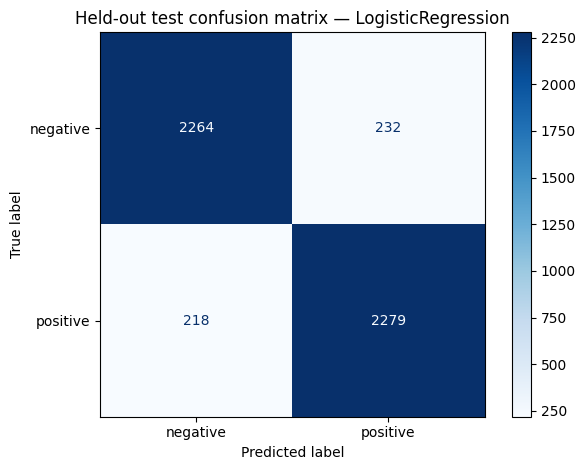

,count,accuracy
length_group,,
"(10.999, 127.0]",1258,0.901431
"(127.0, 174.0]",1250,0.915200
"(174.0, 283.0]",1239,0.906376
"(283.0, 2470.0]",1246,0.916533


False positives: 232
False negatives: 218

 false_positive
 - I saw this film right in the middle while going through a breakup. It was about 3 in the morning and I was battling insomnia with a quick snack. It wasn't too bad at the time, but every time I have tried to watch it since, I can't get into it like I did that night.<br /><br />At the time I thought it was cute and I loved the variety of characters, though they totally could have done better than Goran V, in my opinion. But the one thing that kept 
 - I was quite impressed with this movie as a child of eight or nine. The gangsters seemed very real and threatening to me, and I could see why people would have been afraid of someone like Dillinger. Seeing it as an adult, it seemed almost comical, owing to the overdone narration and jarring details like Thirties gangsters driving cars that looked like they were from the Fifties. There is a certain gritty, unglamorous reality to the way the crimina
 - Looked forward to viewing this

In [19]:
X_test=test_df.review.reset_index(drop=True); y_test=test_df.label.reset_index(drop=True)
test_pred=selected_model.predict(X_test)
test_metrics=metrics(y_test,test_pred)
print('TEST metrics:',test_metrics)
print(classification_report(y_test,test_pred,target_names=['negative','positive']))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=['negative','positive'],cmap='Blues')
plt.title(f'Held-out test confusion matrix — {selected_name}')
plt.tight_layout();plt.savefig(ROOT/'figures'/'test_confusion_matrix.png',dpi=160);plt.show()
error_df=pd.DataFrame({'review':X_test,'actual':y_test,'predicted':test_pred})
error_df['correct']=error_df.actual.eq(error_df.predicted)
error_df['word_count']=error_df.review.str.split().str.len()
error_df['length_group']=pd.qcut(error_df.word_count,4,duplicates='drop')
length_stats=error_df.groupby('length_group',observed=True).agg(
    count=('correct','size'),accuracy=('correct','mean'))
display(length_stats)
length_stats.to_csv(ROOT/'artifacts'/'error_by_length.csv')
print('False positives:',int(((error_df.actual==0)&(error_df.predicted==1)).sum()))
print('False negatives:',int(((error_df.actual==1)&(error_df.predicted==0)).sum()))
for kind,mask in [('false_positive',(error_df.actual==0)&(error_df.predicted==1)),
                  ('false_negative',(error_df.actual==1)&(error_df.predicted==0))]:
    print('\n',kind)
    for example in error_df.loc[mask,'review'].head(3):print(' -',example[:450].replace('\n',' '))
error_df.to_csv(ROOT/'artifacts'/'test_predictions_for_error_analysis.csv',index=False)
with mlflow.start_run(run_name=f'heldout_test_{selected_name}'):
    mlflow.log_param('model_type',selected_name)
    mlflow.log_metrics({f'test_{k}':v for k,v in test_metrics.items()})
    mlflow.log_artifact(str(ROOT/'figures'/'test_confusion_matrix.png'))
    mlflow.log_artifact(str(ROOT/'artifacts'/'error_by_length.csv'))